In [ ]:
Name: Sadhna
Course: B.Sc(hons.) Data Science
Roll No.: 2601840007

In [ ]:
Retail Product Category Sales Analysis
Capstone project notebook · AML002 Introduction to Data Science

Research question
Which product categories contribute the most to total sales revenue in this dataset, and how do their transaction counts, quantities sold, and average transaction values compare?

This notebook uses the supplied retail transactions file.
It ranks categories using recorded Total Amount, calculates each category's share of total revenue, and visualises the differences.
Read the notes in each section and write your own interpretation in the final cells.

In [ ]:
Project objective and scope
Objective: Group retail transactions by Product Category and compare revenue, quantity sold, number of transactions, average order value, and revenue contribution.

Dataset period: The dates in the supplied file will be checked after loading. Conclusions describe only this dataset and period;
they should not be treated as a forecast or as results for all retailers.

Average order value (AOV): Here, AOV means the mean recorded Total Amount per transaction in a category.
The file has a transaction ID, so each row is treated as one transaction after checking for duplicate IDs.

In [ ]:
# 1. Importing Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
from google.colab import files

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# 2. Load the CSV file
# When prompted, choose the file retail_sales_dataset.csv from your computer. In Google Colab, this upload lasts only for the current runtime.

uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))
print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())

Saving retail_sales_dataset.csv to retail_sales_dataset (1).csv
Dataset loaded successfully!
Rows and columns: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [ ]:
# 3. Understand the data
# The dataset contains one row per recorded transaction. We will inspect column names, data types, missing values,and summary statistics before analysing the categories.

print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

Statistical summary:


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [ ]:
# 4. Check missing values and duplicates
# Check whether any columns contain missing values or repeated rows before cleaning.

print("Missing values in each column:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())
if "Transaction ID" in df.columns:
    print("Repeated transaction IDs:", df["Transaction ID"].duplicated().sum())

print("\nProduct categories:")
print(df["Product Category"].value_counts())

Missing values in each column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate rows: 0
Repeated transaction IDs: 0

Product categories:
Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64


In [ ]:
# 5. Clean and validate the data
# We convert date and numeric fields to their proper types, remove exact duplicate rows, and check for missing or invalid values.
# The analysis requires a category, date, quantity, and total amount. Rows missing those required fields cannot be used for category comparisons.

data = df.copy()
data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
for column in ["Quantity", "Price per Unit", "Total Amount"]:
    data[column] = pd.to_numeric(data[column], errors="coerce")

rows_before = len(data)
data = data.drop_duplicates()
print("Exact duplicate rows removed:", rows_before - len(data))

required_columns = ["Date", "Product Category", "Quantity", "Total Amount"]
missing_required = data[required_columns].isna().any(axis=1).sum()
print("Rows missing a required analysis value:", missing_required)
data = data.dropna(subset=required_columns)
data["Product Category"] = data["Product Category"].astype(str).str.strip()
data = data[data["Product Category"] != ""]

if "Transaction ID" in data.columns:
    print("Repeated transaction IDs:", data["Transaction ID"].duplicated().sum())
print("Rows available for analysis:", len(data))
print("Negative quantities:", (data["Quantity"] < 0).sum())
print("Negative total amounts:", (data["Total Amount"] < 0).sum())

Exact duplicate rows removed: 0
Rows missing a required analysis value: 0
Repeated transaction IDs: 0
Rows available for analysis: 1000
Negative quantities: 0
Negative total amounts: 0


In [ ]:
# 6. Check the recorded sales period
# The period is calculated directly from valid dates in the dataset. Include this period when describing the scope
# of the findings.

start_date = data["Date"].min()
end_date = data["Date"].max()
print("Recorded period:", start_date.strftime("%d %B %Y"), "to", end_date.strftime("%d %B %Y"))
print("Calendar days between first and last date:", (end_date - start_date).days)

Recorded period: 01 January 2023 to 01 January 2024
Calendar days between first and last date: 365


In [ ]:
# 7. Calculate category performance
# For each category, calculate total revenue, total quantity, transaction count, average transaction value,
# and share of total revenue. Revenue share is category revenue divided by revenue across all included rows.

category_summary = (
    data.groupby("Product Category")
        .agg(
            Total_Revenue=("Total Amount", "sum"),
            Quantity_Sold=("Quantity", "sum"),
            Transactions=("Transaction ID", "nunique"),
            Average_Order_Value=("Total Amount", "mean")
        )
        .sort_values("Total_Revenue", ascending=False)
)
total_revenue = data["Total Amount"].sum()
category_summary["Revenue_Share_Percent"] = category_summary["Total_Revenue"] / total_revenue * 100

display(category_summary.style.format({
    "Total_Revenue": "{:,.2f}",
    "Quantity_Sold": "{:,.0f}",
    "Transactions": "{:,.0f}",
    "Average_Order_Value": "{:,.2f}",
    "Revenue_Share_Percent": "{:.1f}%"
}).set_caption("Product category performance (ranked by total revenue)"))

,Total_Revenue,Quantity_Sold,Transactions,Average_Order_Value,Revenue_Share_Percent
Product Category,,,,,
Electronics,"156,905.00",849,342,458.79,34.4%
Clothing,"155,580.00",894,351,443.25,34.1%
Beauty,"143,515.00",771,307,467.48,31.5%


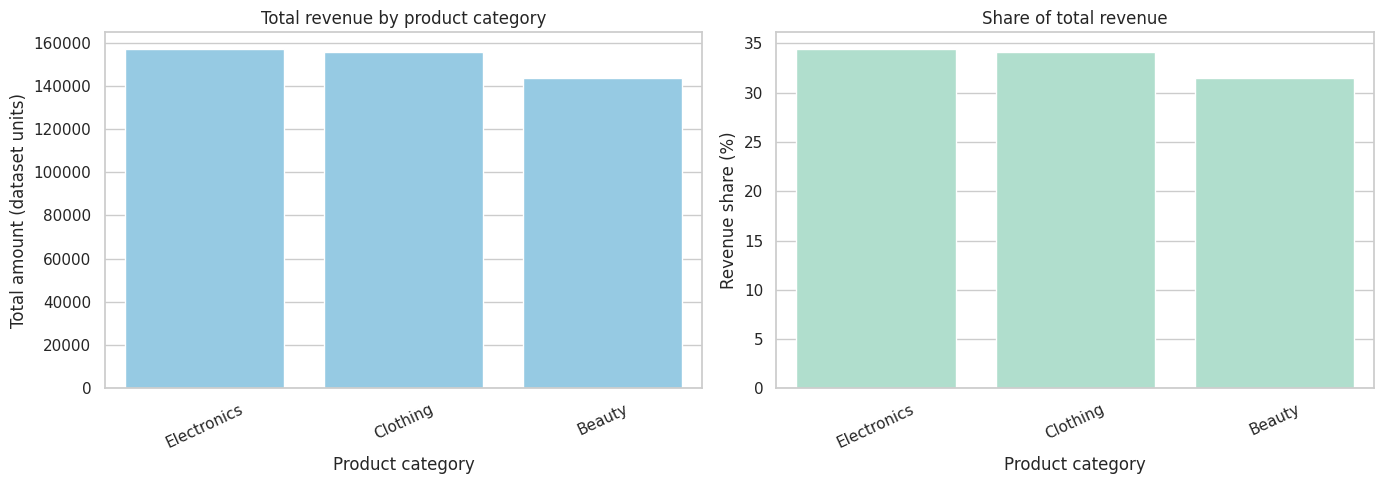

In [ ]:
# 8. Visualise the category comparison
# The first chart compares total revenue. The second shows revenue share as percentages.

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
plot_data = category_summary.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=plot_data, x="Product Category", y="Total_Revenue", ax=axes[0], color="#89CFF0")
axes[0].set_title("Total revenue by product category")
axes[0].set_xlabel("Product category")
axes[0].set_ylabel("Total amount (dataset units)")
axes[0].tick_params(axis="x", rotation=25)
sns.barplot(data=plot_data, x="Product Category", y="Revenue_Share_Percent", ax=axes[1], color="#A8E6CF")
axes[1].set_title("Share of total revenue")
axes[1].set_xlabel("Product category")
axes[1].set_ylabel("Revenue share (%)")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

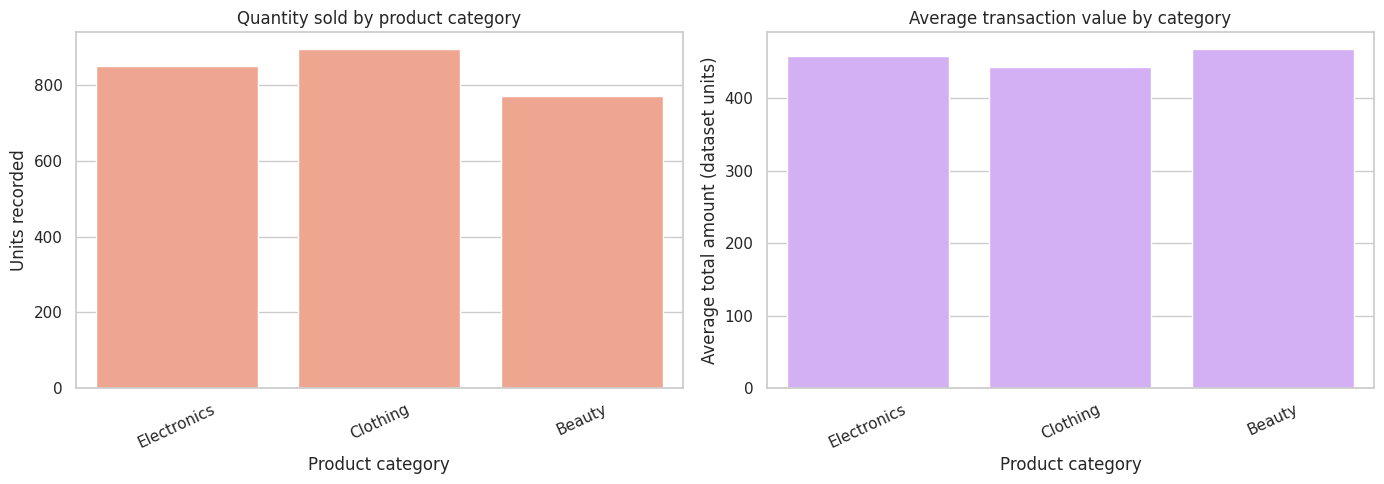


Quantity and average order value: This chart checks whether revenue patterns align with units sold and average transaction value.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=plot_data, x="Product Category", y="Quantity_Sold",
            ax=axes[0], color="#FF9E80")
axes[0].set_title("Quantity sold by product category")
axes[0].set_xlabel("Product category")
axes[0].set_ylabel("Units recorded")
axes[0].tick_params(axis="x", rotation=25)
sns.barplot(data=plot_data, x="Product Category", y="Average_Order_Value",
            ax=axes[1], color="#D4A5FF")
axes[1].set_title("Average transaction value by category")
axes[1].set_xlabel("Product category")
axes[1].set_ylabel("Average total amount (dataset units)")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()
print("\nQuantity and average order value: This chart checks whether revenue patterns align with units sold and average transaction value.")




In [ ]:
# 9. Key findings (generated from this dataset)
# The statements below are generated from the table.
# Review the outputs and explain what they mean in your own words.

highest_revenue_category = category_summary["Total_Revenue"].idxmax()
lowest_revenue_category = category_summary["Total_Revenue"].idxmin()
highest_revenue = category_summary.loc[highest_revenue_category, "Total_Revenue"]
lowest_revenue = category_summary.loc[lowest_revenue_category, "Total_Revenue"]
highest_share = category_summary.loc[highest_revenue_category, "Revenue_Share_Percent"]

print(f"Highest revenue category: {highest_revenue_category} ({highest_revenue:,.2f} dataset units).")
print(f"Lowest revenue category: {lowest_revenue_category} ({lowest_revenue:,.2f} dataset units).")
print(f"{highest_revenue_category} contributed {highest_share:.1f}% of included revenue.")
print(f"Revenue difference between these categories: {highest_revenue - lowest_revenue:,.2f} dataset units.")
print("\nFull ranking:")
for rank, (category, row) in enumerate(category_summary.iterrows(), start=1):
    print(f"{rank}. {category}: {row['Total_Revenue']:,.2f} revenue; "
          f"{row['Quantity_Sold']:,.0f} units; "
          f"{row['Transactions']} transactions; "
          f"average order value {row['Average_Order_Value']:,.2f}.")

Highest revenue category: Electronics (156,905.00 dataset units).
Lowest revenue category: Beauty (143,515.00 dataset units).
Electronics contributed 34.4% of included revenue.
Revenue difference between these categories: 13,390.00 dataset units.

Full ranking:
1. Electronics: 156,905.00 revenue; 849 units; 342.0 transactions; average order value 458.79.
2. Clothing: 155,580.00 revenue; 894 units; 351.0 transactions; average order value 443.25.
3. Beauty: 143,515.00 revenue; 771 units; 307.0 transactions; average order value 467.48.


In [ ]:
print("\n10. Your interpretation: Electronics ranked first, with 156,905 dataset units in revenue (34.4% of the total).")
print("\nClothing was close behind at 155,580 (34.1%), while Beauty ranked lowest at 143,515 (31.5%).")
print("\nClothing had the most units sold and transactions, but Beauty had the highest average transaction value. So, quantity alone does not explain the revenue ranking.")
print("\n11. Conclusion: Electronics generated the most recorded revenue and Beauty the least among the 1,000 transactions dated 1 January 2023 to 1 January 2024.")
print("\n The dataset does not specify a currency or include product costs, so the results compare recorded revenue only and cannot show profitability.")


10. Your interpretation: Electronics ranked first, with 156,905 dataset units in revenue (34.4% of the total).

Clothing was close behind at 155,580 (34.1%), while Beauty ranked lowest at 143,515 (31.5%).

Clothing had the most units sold and transactions, but Beauty had the highest average transaction value.

So, quantity alone does not explain the revenue ranking.

11. Conclusion: Electronics generated the most recorded revenue and Beauty the least among the 1,000 transactions dated 1 January 2023 to 1 January 2024.

 The dataset does not specify a currency or include product costs, so the results compare recorded revenue only and cannot show profitability.
